# Ranges, distributions and outliers

Before modelling anything we should know the data's **shape**. What range does each quantity
span? How is it distributed? Which values look suspicious?

Three kinds of outlier check are worth separating:

| Check | Question | Example |
|---|---|---|
| **Physical bounds** | Is the value possible at all? | insolation above the solar constant |
| **Statistical / spatial** | Is it unusual *given its neighbours*? | one sampler 20× hotter than the posts beside it |
| **Cross-table consistency** | Do two independent measurements agree? | plume direction vs. wind direction |

An outlier is a question, not a verdict. The data set never "corrects" a printed value. These
checks only point you at cells worth a look on the scan (`printed_page`, `cell_id`).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))  # notebooks/ (for pgdata)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pgdata
pgdata.style()
pd.set_option("display.precision", 3); pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)

In [2]:
arcs, towers = pgdata.arcs(), pgdata.towers()
rt = pgdata.run_table()
summ = pgdata.arc_summary()

## 1. What a cell can hold

In [3]:
pd.concat({"arcs": arcs.status.value_counts(), "towers": towers.status.value_counts()}, axis=1)

,arcs,towers
status,,
not_measurable,22306,1700
value,8173,1096
missing,31,12
unread,0,0


## 2. Concentrations span five orders of magnitude

Look at the minimum and maximum on each arc. Concentrations near the source reach hundreds of
mg m⁻³, while the edges of the 800 m plume are below 0.1. With a range like that, **always look
on a log scale**: a linear histogram is one tall bar at zero.

In [4]:
v = arcs[arcs.status == "value"]
desc = v.groupby("arc_m").concentration_mg_m3.describe(percentiles=[.05, .25, .5, .75, .95])
desc["printed_zero"] = v[v.concentration_mg_m3 == 0].groupby("arc_m").size()
desc.fillna({"printed_zero": 0})

,count,mean,std,min,5%,25%,50%,75%,95%,max,printed_zero
arc_m,,,,,,,,,,,
50,2054.0,89.486,122.559,0.005,0.090,4.748,42.850,131.750,312.000,1000.0,0.0
100,1713.0,37.235,71.783,0.010,0.080,2.810,15.200,42.600,152.400,822.0,0.0
200,1443.0,14.079,34.935,0.005,0.045,1.040,3.990,12.350,59.470,490.0,0.0
400,1174.0,4.942,13.440,0.005,0.035,0.330,1.095,3.440,21.415,146.0,0.0
800,1789.0,1.525,5.940,0.000,0.025,0.080,0.225,0.745,6.112,104.0,2.0


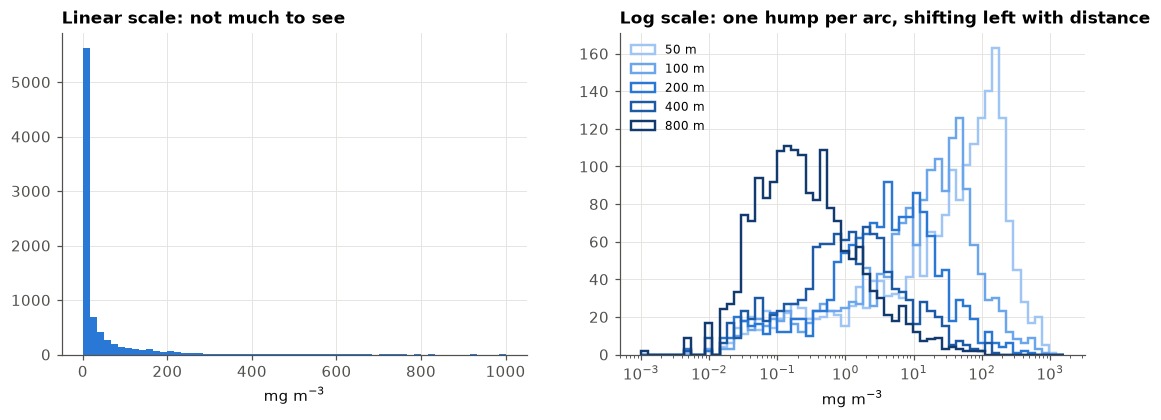

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(v.concentration_mg_m3, bins=60, color=pgdata.ARC_COLORS[200])
axes[0].set_title("Linear scale: not much to see"); axes[0].set_xlabel("mg m$^{-3}$")
bins = np.logspace(-3, 3.2, 60)
for arc in pgdata.ARCS_M:
    axes[1].hist(v[v.arc_m == arc].concentration_mg_m3.clip(lower=1e-3), bins=bins, histtype="step", lw=1.6,
                 color=pgdata.ARC_COLORS[arc], label=f"{arc} m")
axes[1].set_xscale("log"); axes[1].set_title("Log scale: one hump per arc, shifting left with distance")
axes[1].set_xlabel("mg m$^{-3}$"); axes[1].legend(fontsize=8)
plt.show()

## 3. Run-level quantities: ranges at a glance

These are the quantities we will model with. Read the min/max columns with a physicist's eye.
Is a 2 m wind of 0.66 m/s plausible on a calm night? Yes. Is a 9 m/s afternoon breeze over a
prairie plausible? Yes. Is a σ_θ of 31.7°? Yes, for a convective afternoon with meandering
eddies.

In [6]:
units = {"Q_g_s": "g/s", "u_ref": "m/s", "u_1m": "m/s", "u_8m": "m/s", "dir_source_10": "deg (from)",
         "sigma_theta_source_10": "deg", "T_1m": "°C", "dT_16_05": "°C", "Ri_b": "-", "wind_exp_p": "-",
         "u_star": "m/s", "rad_net_radiation": "cal cm-2 s-1", "rad_insolation": "cal cm-2 s-1",
         "peak_100": "mg m-3", "sigma_y_m_100": "m", "cwic_100": "mg m-2"}
tab = rt[list(units)].describe().T[["count", "min", "25%", "50%", "75%", "max"]]
tab.insert(0, "unit", pd.Series(units))
tab

,unit,count,min,25%,50%,75%,max
Q_g_s,g/s,68.0,38.500,43.325,7.965e+01,98.950,104.100
u_ref,m/s,68.0,0.440,3.110,4.520e+00,6.307,9.000
u_1m,m/s,68.0,0.660,2.540,4.040e+00,5.470,8.460
u_8m,m/s,66.0,2.110,4.210,5.900e+00,7.700,11.300
dir_source_10,deg (from),63.0,128.000,166.000,1.810e+02,198.000,245.000
sigma_theta_source_10,deg,63.0,3.200,5.700,7.300e+00,10.650,25.600
T_1m,°C,68.0,15.150,20.025,2.443e+01,30.575,36.060
dT_16_05,°C,58.0,-7.930,-2.465,5.100e-01,1.447,6.380
Ri_b,-,66.0,-0.755,-0.076,9.204e-03,0.050,0.447
wind_exp_p,-,68.0,0.113,0.155,1.789e-01,0.241,0.778


### Day versus night, side by side

Boxplots split by time of day. Notice how **every** quantity separates. Daytime has stronger
winds, larger direction fluctuations (σ_θ), negative ΔT (cooler aloft, which drives convection)
and wider plumes. Keep this in mind for notebook 07: when everything differs by day and night,
almost everything will correlate with everything else.

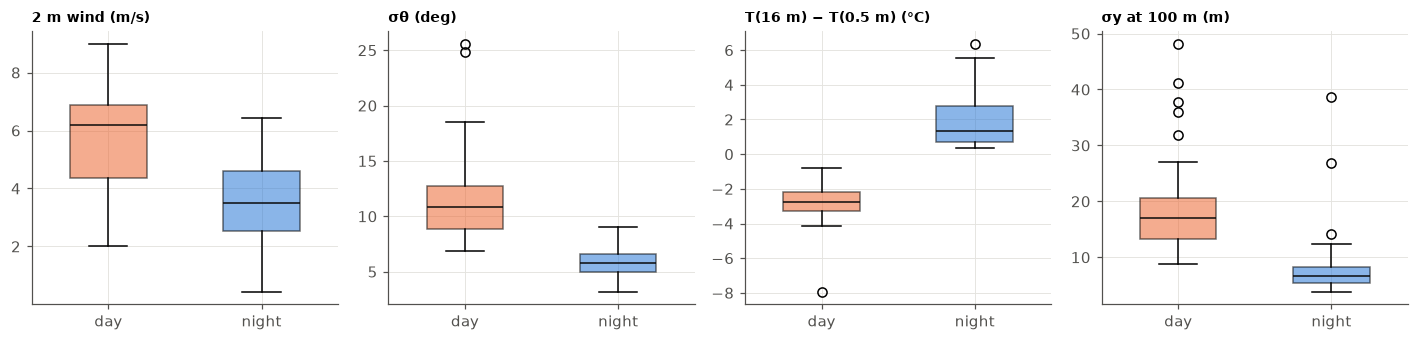

In [7]:
show = ["u_ref", "sigma_theta_source_10", "dT_16_05", "sigma_y_m_100"]
labels = ["2 m wind (m/s)", "σθ (deg)", "T(16 m) − T(0.5 m) (°C)", "σy at 100 m (m)"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, c, lab in zip(axes, show, labels):
    data = [rt.loc[rt.day_night == k, c].dropna() for k in ["day", "night"]]
    bp = ax.boxplot(data, tick_labels=["day", "night"], patch_artist=True, widths=0.5, medianprops=dict(color=pgdata.INK))
    for patch, col in zip(bp["boxes"], ["#eb6834", "#2a78d6"]):
        patch.set_facecolor(col); patch.set_alpha(0.55)
    ax.set_title(lab, fontsize=9)
plt.tight_layout(); plt.show()

## 4. Physical-bounds check: the case of the misplaced decimal point

The upper bound on solar radiation at the ground is the **solar constant**, about
0.033 cal cm⁻² s⁻¹ (1361 W m⁻²). Let us look at every radiation value in Table 8.1.

In [8]:
mm = pgdata.micromet()
rad = mm[mm.section == "radiation"]
rad.groupby("quantity").value.describe()[["count", "min", "50%", "max"]]

,count,min,50%,max
quantity,,,,
insolation,40.0,0.000e+00,1.550e-02,183.000
net_radiation,69.0,-7.200e-03,-6.700e-04,0.015
reflected,23.0,8.000e-04,2.900e-03,0.004


In [9]:
rad[rad.value.abs() > 0.033][["release", "date", "cst", "quantity", "token", "value", "quality", "check_failures", "printed_page"]]

,release,date,cst,quantity,token,value,quality,check_failures,printed_page
507,16,1956-07-23,1005,insolation,0183,183.0,printed_inconsistent,format,56


Release 16's insolation is printed **`0183`**, without the decimal point, so it parses as 183.
The data set already says so: `quality = printed_inconsistent`, `check_failures = format`. The
printed token is kept as is, and the analyst decides. The intended value is almost certainly
`.0183`. `run_table()` simply drops radiation values above the bound.

Lesson: **`describe()` is your first outlier detector.** A maximum four orders of magnitude
above the median is not weather.

The same check applied to the other Table 8.1 quantities:

In [10]:
bounds = {"temperature": (-10, 50), "vapor_pressure": (0, 60), "wind_speed": (0, 25),
          "wind_direction": (0, 360), "soil_temperature_change": (-15, 15)}
rows = []
for sec, (lo, hi) in bounds.items():
    s = mm[mm.quantity == sec]   # by quantity: the soil section also holds start times (hhmm)
    out = s[(s.value_si < lo) | (s.value_si > hi)]
    rows.append({"section": sec, "n": len(s), "min": s.value_si.min(), "max": s.value_si.max(),
                 "bounds": f"[{lo}, {hi}]", "outside": len(out)})
pd.DataFrame(rows)

,section,n,min,max,bounds,outside
0,temperature,929,13.990,38.64,"[-10, 50]",0
1,vapor_pressure,438,9.220,24.31,"[0, 60]",0
2,wind_speed,476,0.022,12.14,"[0, 25]",0
3,wind_direction,64,97.000,226.00,"[0, 360]",0
4,soil_temperature_change,366,-1.800,1.87,"[-15, 15]",0


Volume II also carries its own **statistical** outlier screen in the `outlier` column (it marks
values and removes nothing). In Table 8.1 it flags three soil-temperature changes:

In [11]:
t81 = pd.read_csv(pgdata.VOL2 / "table_8.1.csv", dtype=str, keep_default_na=False)
t81[t81.outlier != ""][["release", "quantity", "height_m", "token", "outlier", "quality", "printed_page"]]

,release,quantity,height_m,token,outlier,quality,printed_page
1245,28,soil_temperature_change,-0.5,-.20,global (-13 scales),two_readers,58
1251,28,soil_temperature_change,-1.0,-.31,global (-20 scales),two_readers,58
1535,33,soil_temperature_change,-0.5,-.11,global (-7 scales),two_readers,59


## 5. Spatial check: isolated spikes on an arc

A real plume is smooth across neighbouring posts. One sampler far above **both** of its
neighbours is suspicious. It may be a reading error, a contaminated sampler (gnats in the
capillary, as in run 25), or genuine small-scale turbulence. We flag posts whose value is more
than **5×** the larger of their two neighbours, where both neighbours were measured.

The same idea, a robust comparison against the local neighbourhood, underlies most
spike detectors.

In [12]:
a = arcs[arcs.status.isin(["value", "not_measurable"])].sort_values(["run", "arc_m", "post"]).copy()
a["c"] = a.concentration_mg_m3.fillna(0.0)
g = a.groupby(["run", "arc_m"]).c
a["left"], a["right"] = g.shift(1), g.shift(-1)
a["nbr_max"] = a[["left", "right"]].max(axis=1)
spikes = a[(a.c > 0) & a.left.notna() & a.right.notna() & (a.c > 5 * a.nbr_max.clip(lower=1e-9))]
print(f"{len(spikes)} isolated spikes out of {(a.c > 0).sum()} measured values")
spikes[["run", "arc_m", "post", "left", "c", "right", "token", "flagged", "reviewed", "printed_page"]] \
    .sort_values("c", ascending=False).head(15)

15 isolated spikes out of 8171 measured values


,run,arc_m,post,left,c,right,token,flagged,reviewed,printed_page
1173,3,400,86,0.250,10.100,0.830,10.1,True,False,85
20862,44,800,69,0.505,9.565,0.575,9.565,True,True,156
4850,10,800,127,0.050,0.900,0.110,0.90,True,False,98
2917,6,800,104,0.020,0.155,0.000,0.155,False,False,91
3249,7,200,73,0.000,0.110,0.000,0.110,False,False,93
24221,52,800,62,0.000,0.035,0.005,0.035,False,False,169
24182,52,800,23,0.000,0.030,0.000,0.030,False,False,169
3199,7,200,23,0.000,0.030,0.000,0.030,True,False,92
24179,52,800,20,0.000,0.020,0.000,0.020,True,False,169
1764,4,800,41,0.000,0.010,0.000,0.010,False,False,86


Most spikes are small values at the **edge** of a plume. There, a 0.05 next to two blanks is a
"spike" only because its neighbours are zero, and that is expected. The ones worth looking at
are **large** values next to measured neighbours. Let us plot the largest one in context:

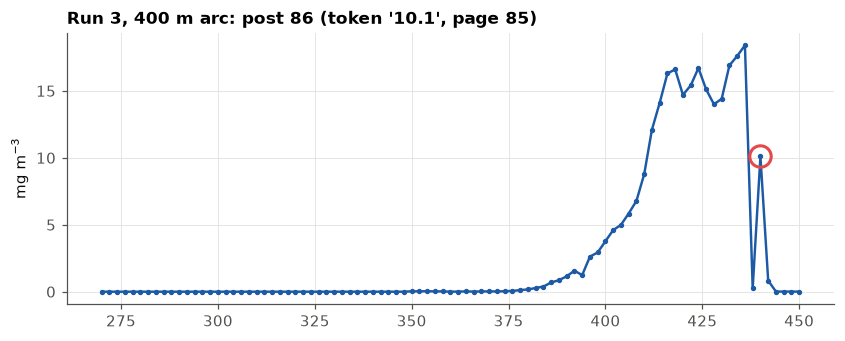

In [13]:
big = spikes[spikes.nbr_max > 0].sort_values("c", ascending=False)
if len(big):
    s = big.iloc[0]
    d = a[(a.run == s.run) & (a.arc_m == s.arc_m)]
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(d.bearing_unwrapped, d.c, ".-", color=pgdata.ARC_COLORS[s.arc_m])
    ax.plot(s.bearing_unwrapped, s.c, "o", mfc="none", mec="#e34948", ms=14, mew=2)
    ax.set_title(f"Run {s.run}, {s.arc_m} m arc: post {s.post} (token {s.token!r}, page {s.printed_page})")
    ax.set_ylabel("mg m$^{-3}$"); plt.show()
else:
    print("no large spikes")

## 6. Consistency check: does the plume go where the wind says?

The wind vane (Table 6.1, 2 m at the source) and the samplers (Table 5.2) are **independent
instruments**. Wind direction is where the wind comes *from*, so the plume centroid should sit
near *direction + 180°*. A large disagreement points at a misread value, a key mix-up, or an
odd run.

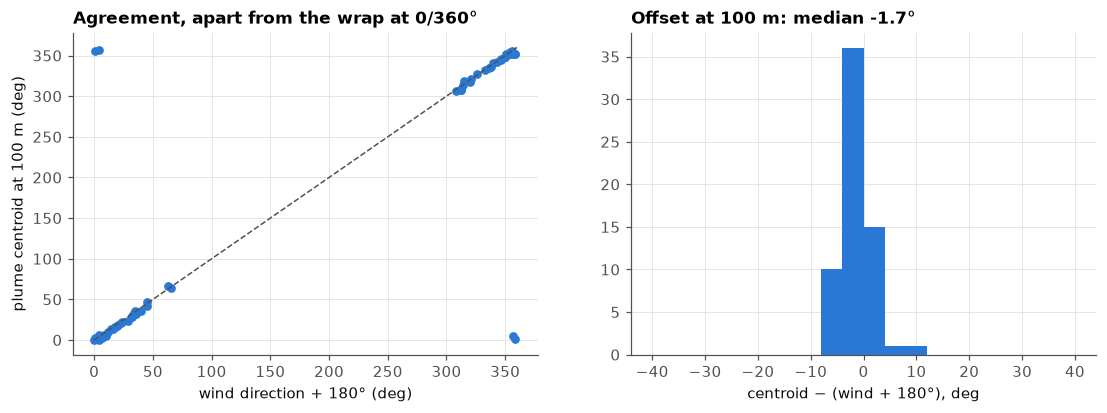

,count,mean,std,min,25%,50%,75%,max
"|offset| at 100 m, deg",63.0,2.5,1.8,0.1,1.1,2.0,3.5,8.2


In [14]:
cen = rt[["dir_source_10", "centroid_deg_100", "centroid_deg_400", "regime"]].dropna(subset=["dir_source_10"])
diff = lambda c: ((cen[c] - (cen.dir_source_10 + 180)) + 180) % 360 - 180
cen["off_100"], cen["off_400"] = diff("centroid_deg_100"), diff("centroid_deg_400")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter((cen.dir_source_10 + 180) % 360, cen.centroid_deg_100, color=pgdata.ARC_COLORS[200], s=22)
axes[0].plot([0, 360], [0, 360], color=pgdata.MUTED, lw=1, ls="--")
axes[0].set_xlabel("wind direction + 180° (deg)"); axes[0].set_ylabel("plume centroid at 100 m (deg)")
axes[0].set_title("Agreement, apart from the wrap at 0/360°")
axes[1].hist(cen.off_100, bins=np.arange(-40, 41, 4), color=pgdata.ARC_COLORS[200])
axes[1].set_xlabel("centroid − (wind + 180°), deg"); axes[1].set_title(f"Offset at 100 m: median {cen.off_100.median():+.1f}°")
plt.show()
cen.off_100.abs().describe().round(1).to_frame("|offset| at 100 m, deg").T

Every run with a vane reading lies within **±8°**, with a median offset near −2°. That is very
good agreement for two instruments 70 years old, and it confirms that the run keys line up
between Volume I's tables. A systematic offset of a few degrees is expected: the vane is a
single 2 m point, and the wind turns slightly with height and distance.

## 7. Consistency check: concentration should fall with distance

For a ground-level source, the peak concentration must fall from arc to arc. A peak that rises
with distance is physically possible (the plume may skirt an arc's sampled range), but it should
be rare.

In [15]:
pk = summ.pivot(index="run", columns="arc_m", values="peak")
rises = (pk.diff(axis=1) > 0)
print("arc pairs where the peak rises with distance:", int(rises.sum().sum()), "of", rises.size - len(pk))
pk[rises.any(axis=1)].round(2)

arc pairs where the peak rises with distance: 5 of 272


arc_m,50,100,200,400,800
run,,,,,
13,174.0,419.0,490.0,131.00,104.00
14,702.0,822.0,402.0,146.00,21.60
3,44.6,246.0,80.0,18.40,0.64
44,191.0,53.9,15.1,3.12,9.56


Two kinds of cases show up here:

- **Runs 3, 13 and 14 are stable, light-wind nights.** At 50 m the plume is only a couple of
  metres wide, narrower than the 1.75 m post spacing, so the true peak can fall *between* posts.
  The first arc then under-reads, and the "rise" is a sampling artefact rather than an error.
- **Run 44, 800 m.** The peak rises from 3.1 to 9.6. That 9.565 is the same post that the spike
  check in section 5 flagged, and it is marked reviewed. Two independent checks agree, so it is
  worth a second look on page 156.

## 8. Data-quality metadata as a dimension

Every cell carries its provenance. Before trusting a pattern, check it does not come from the
weaker readings. Here: which Table 8.1 cells depend on context or remain doubtful, and in which
sections are they?

In [16]:
pd.crosstab(t81.section, t81.quality)

quality,context,doubtful,owner,printed_inconsistent,rule,single_reader,two_readers
section,,,,,,,
precipitation,0,0,12,0,0,59,0
radiation,2,0,0,2,0,0,209
soil_temperature_change,17,11,0,0,0,1,539
temperature,10,27,0,10,3,1,943
vapor_pressure,2,8,0,3,2,0,553
wind_direction,4,0,0,0,0,0,67
wind_speed,10,13,0,10,0,0,464


**Takeaways**

- Concentrations need a log scale. Profiles need blanks treated as zero, and `M` (missing) excluded.
- One misplaced decimal point in Table 8.1 (release 16 insolation); `run_table()` excludes it.
- The arcs are smooth, and the few large spikes are listed above for a look at the scan.
- Wind direction and plume direction agree within ±8°: the run keys line up across tables.
- Day/night separation is strong in every variable. That is the subject of the next notebook.